# DSpark v2 训练 · 运行与监控

**训练代码就是 [`train/pb_train_v2.py`](pb_train_v2.py)**（官方 DeepSpec 配方；旧的 `pb_train.py` 是第一版 1.806 用的，保留作对照）。三个脚本的关系：

| 文件 | 作用 |
| --- | --- |
| [`pb_gen_worker.py`](pb_gen_worker.py) | ① 数据生成：target 以 **T=0.7 / top_p 0.8 / top_k 20** 给每条 prompt 生成 response（可断点续跑，按 id 跳过已完成） |
| [`pb_train_v2.py`](pb_train_v2.py) | ② 训练：γ=4 加权平均 loss（0.1·CE + 0.9·L1 + 1.0·BCE）、AdamW 6e-4 + cosine(4% warmup)、wd 0、bf16、每序列多 anchor；每 1000 步在 200 条 val 上评 τ 并存 `best.pt`/`last.pt` |
| [`pb_pipeline_v2.sh`](pb_pipeline_v2.sh) | 一键流水线：等生成完 → 校验齐全 → 显存探针 → 自动启动两个训练 |

输入 / 输出：

| 路径 | 内容 |
| --- | --- |
| `/home/dev/KAP/data/pb_dspark/prompts.pt` | 50,500 条 prompt（50,000 train + 500 val，已切分） |
| `/home/dev/KAP/data/pb_dspark/gen07/` | 0.7/0.8/20 生成的 response —— **训练数据** |
| `/home/dev/KAP/data/pb_dspark/gen/` | T=1.0 生成的 response —— 论文口径评测（τ_paper）用 |
| `/home/dev/KAP/parameter/draft/dspark_pb_v2_a/` | 运行 A 权重（`best.pt`/`last.pt`）+ `train_log.jsonl` |
| `/home/dev/KAP/parameter/draft/dspark_pb_v2_b/` | 运行 B 权重 + 日志 |

**当前状态（2026-11-14）**：A 已完成（30,860 步，τ_paper **2.133**，第一版是 1.806）；B 进行中（τ_paper 2.137 @ 47k/61,710 步）。完整差距分析和配方依据见 [`doc/DSpark-训练文档.md`](../doc/DSpark-训练文档.md) §12。

## 0. 状态检查（可随时运行）

In [12]:
!nvidia-smi --query-gpu=index,utilization.gpu,memory.used,memory.total --format=csv,noheader
!pgrep -af pb_train_v2.py || echo "(没有训练进程在运行)"
print('--- 运行 A 日志末尾 ---')
!tail -n 2 /home/dev/KAP/data/pb_dspark/train_v2_a.log
print('--- 运行 B 日志末尾 ---')
!tail -n 2 /home/dev/KAP/data/pb_dspark/train_v2_b.log

0, 0 %, 10875 MiB, 49140 MiB
1, 0 %, 3 MiB, 49140 MiB
2175940 /bin/bash -c pgrep -af pb_train_v2.py || echo "(没有训练进程在运行)"
--- 运行 A 日志末尾 ---
step  30860  tau_paper 2.133  tau_indist 2.528  alpha 0.61 0.50 0.45 0.41 0.38 0.35 0.32  lr 0.00e+00
done 38211 s  best tau_paper 2.133
--- 运行 B 日志末尾 ---
step  61710  tau_paper 2.159  tau_indist 2.591  alpha 0.62 0.50 0.46 0.41 0.38 0.35 0.33  lr 0.00e+00
done 59594 s  best tau_paper 2.159


## 1. 数据生成（已完成，重跑会自动跳过）

gen07/ 里已有 50,500 条（2026-11-14 00:29 校验齐全）。**只有换模型、换采样参数或换 max_new 时才需要重新生成**；同参数重跑安全（按 id 断点续跑），但会占满两张卡约 2.5 小时。

```
cd /home/dev/KAP/train
nohup env CUDA_VISIBLE_DEVICES=0 /home/dev/venv/bin/python -I pb_gen_worker.py --rank 0 --world 2 \
    --work /home/dev/KAP/data/pb_dspark --target /home/dev/KAP/parameter/target/Qwen3.5-0.8B-Base-original \
    --max-new 1024 --temperature 0.7 --top-p 0.8 --top-k 20 --bs 96 --out gen07 \
    > /home/dev/KAP/data/pb_dspark/gen07/log_r0.txt 2>&1 &
nohup env CUDA_VISIBLE_DEVICES=1 /home/dev/venv/bin/python -I pb_gen_worker.py --rank 1 --world 2 \
    --work /home/dev/KAP/data/pb_dspark --target /home/dev/KAP/parameter/target/Qwen3.5-0.8B-Base-original \
    --max-new 1024 --temperature 0.7 --top-p 0.8 --top-k 20 --bs 96 --out gen07 \
    > /home/dev/KAP/data/pb_dspark/gen07/log_r1.txt 2>&1 &
```

关键参数：`--max-new 1024`（官方 4096 的折中）、`--temperature/--top-p/--top-k`（官方推荐采样参数）、`--out gen07`（与旧 T=1.0 数据分开存）。

## 2. 训练（pb_train_v2.py）

**参数表**：

| 参数 | 默认 | 说明 |
| --- | --- | --- |
| `--anchors` | 32 | 每序列采样的 anchor 数（官方 512；这是 v2 相对 v1 最大的改动之一） |
| `--seqs` | 16 | 每步序列数；blocks/步 = anchors × seqs（32×16 = 512，实测 28.6 GB） |
| `--epochs` | 10 | 官方同款 |
| `--lr` | 6e-4 | 官方 |
| `--warmup` | 0.04 | 线性 warmup 后 cosine 到 0（官方） |
| `--gamma` | 4.0 | loss 位置衰减 w_k = exp(−(k−1)/γ)（官方 4，v1 误用 7） |
| `--eval-every` | 1000 | 每 N 步评一次 τ 并存 best/last |
| `--out` | 必填 | 权重与日志目录 |
| `--resume` | 开关 | 从 `last.pt` 断点续训（调度按总步数对齐） |
| `--probe` | 开关 | 只跑 3 步，打印峰值显存和每步耗时后退出 |

**两个运行的配置**（当时两张卡各跑一个）：

- 运行 A：`--anchors 32 --seqs 16` → 512 blocks/步，49,376 序列 × 10 epochs = 30,860 步
- 运行 B：`--anchors 64 --seqs 8` → 同样 512 blocks/步，但每序列覆盖翻倍，61,710 步

**启动前必须确认两张卡空闲**（上面 §0 的 nvidia-smi）。启动命令（去掉行首 `#` 才会执行）：

In [13]:
cd /home/dev/KAP/train
# nohup env CUDA_VISIBLE_DEVICES=0 /home/dev/venv/bin/python -I pb_train_v2.py --anchors 32 --seqs 16 --epochs 10 \
#     --out /home/dev/KAP/parameter/draft/dspark_pb_v2_a > /home/dev/KAP/data/pb_dspark/train_v2_a.log 2>&1 &
# nohup env CUDA_VISIBLE_DEVICES=1 /home/dev/venv/bin/python -I pb_train_v2.py --anchors 64 --seqs 8 --epochs 10 \
#     --out /home/dev/KAP/parameter/draft/dspark_pb_v2_b > /home/dev/KAP/data/pb_dspark/train_v2_b.log 2>&1 &
print('启动命令已注释：先跑 §0 确认 GPU 空闲，再去掉 # 执行；断点续训在命令末尾加 --resume')

NameError: name 'cd' is not defined

## 3. 训练曲线（只读文件，随时可运行）

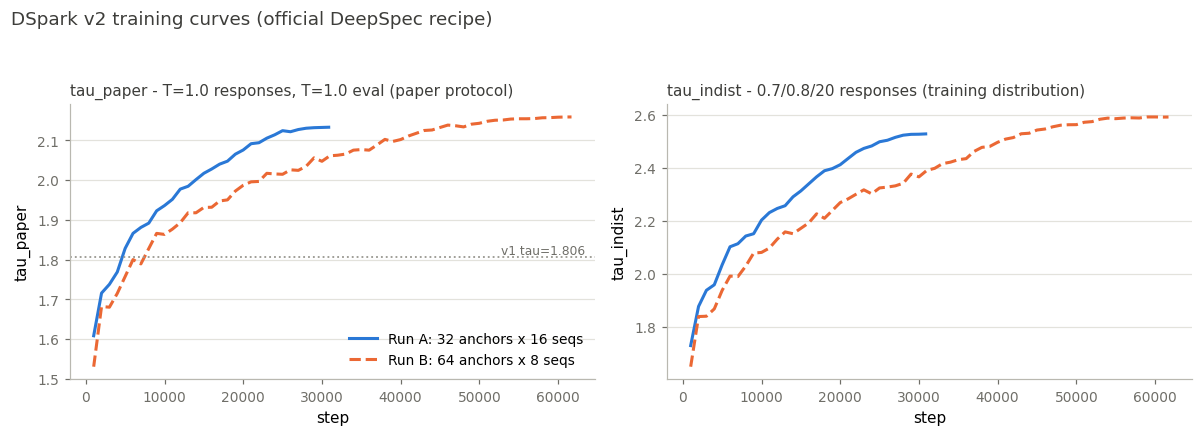

In [ ]:
import json
import matplotlib.pyplot as plt

BLUE, ORANGE = '#2a78d6', '#eb6834'          # 已通过色觉/对比度校验的分类色
INK, MUTE, GRID = '#3d3d3a', '#6f6e68', '#e3e2dc'
OLD_TAU = 1.806                               # 第一版训练（同评测口径）的 tau_paper

def read(tag):
    try:
        return [json.loads(l) for l in open(f'/home/dev/KAP/parameter/draft/dspark_pb_v2_{tag}/train_log.jsonl')]
    except FileNotFoundError:
        return []

A, B = read('a'), read('b')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=110)
panels = [('tau_paper', 'tau_paper - T=1.0 responses, T=1.0 eval (paper protocol)'),
          ('tau_indist', 'tau_indist - 0.7/0.8/20 responses (training distribution)')]
for ax, (key, title) in zip(axes, panels):
    for recs, name, color, ls in ((A, 'Run A: 32 anchors x 16 seqs', BLUE, '-'),
                                  (B, 'Run B: 64 anchors x 8 seqs', ORANGE, '--')):
        if recs:
            ax.plot([r['step'] for r in recs], [r[key] for r in recs], color=color, lw=2, ls=ls, label=name)
    ax.set_xlabel('step'); ax.set_ylabel(key)
    ax.set_title(title, fontsize=10, color=INK, loc='left')
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color('#b9b8b0')
    ax.tick_params(colors=MUTE, labelsize=9)
if A:
    axes[0].axhline(OLD_TAU, color='#9a9992', lw=1.2, ls=':')
    axes[0].annotate(f'v1 tau={OLD_TAU}', xy=(0.98, OLD_TAU), xycoords=('axes fraction', 'data'),
                     ha='right', va='bottom', fontsize=8, color=MUTE)
axes[0].legend(frameon=False, fontsize=9, loc='lower right')
fig.suptitle('DSpark v2 training curves (official DeepSpec recipe)', color=INK, fontsize=12, x=0.01, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### 3.1 接受率 α 随训练的变化（每个草稿位置）

αₖ = Σ min(pₖ, qₖ) 是第 k 个草稿位置在 T=1.0 随机接受下的接受概率（τ_paper 口径，每 1000 步在 200 条 val 上评一次）。7 条线用同一色相由浅到深表示位置 1→7：**训练好不好，看的是所有位置的 α 是否整体上移**（第一版最终 α₁ 只有 0.50，v2 到 0.61）。

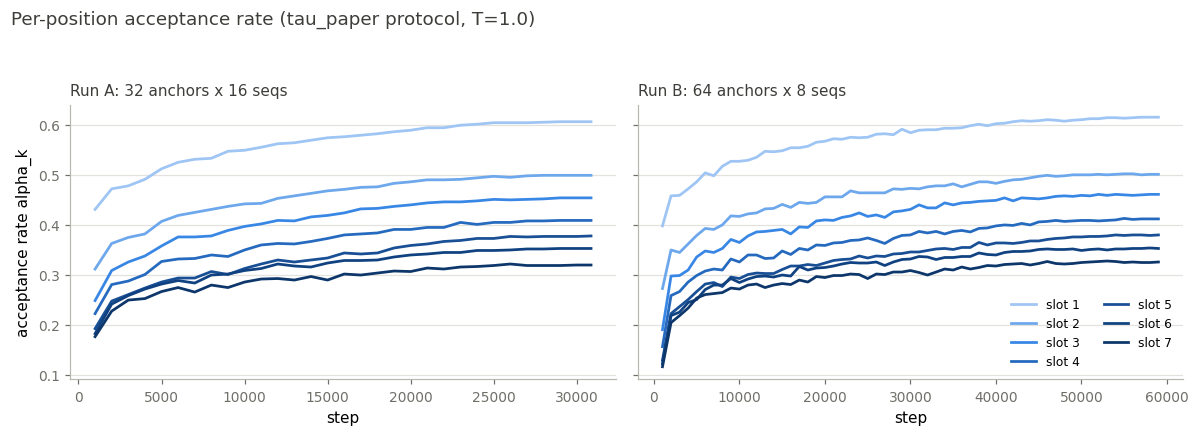

In [ ]:
import json
import matplotlib.pyplot as plt

INK, MUTE, GRID = '#3d3d3a', '#6f6e68', '#e3e2dc'
RAMP = ['#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#104281', '#0d366b']  # slot 1..7, one hue light->dark

def read(tag):
    try:
        return [json.loads(l) for l in open(f'/home/dev/KAP/parameter/draft/dspark_pb_v2_{tag}/train_log.jsonl')]
    except FileNotFoundError:
        return []

A, B = read('a'), read('b')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=110, sharey=True)
for ax, recs, title in ((axes[0], A, 'Run A: 32 anchors x 16 seqs'), (axes[1], B, 'Run B: 64 anchors x 8 seqs')):
    for k in range(7):
        ax.plot([r['step'] for r in recs], [r['alpha_paper'][k] for r in recs],
                color=RAMP[k], lw=1.8, label=f'slot {k+1}')
    ax.set_xlabel('step'); ax.set_title(title, fontsize=10, color=INK, loc='left')
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color('#b9b8b0')
    ax.tick_params(colors=MUTE, labelsize=9)
axes[0].set_ylabel('acceptance rate alpha_k')
axes[1].legend(frameon=False, fontsize=8, ncol=2, loc='lower right')
fig.suptitle('Per-position acceptance rate (tau_paper protocol, T=1.0)', color=INK, fontsize=12, x=0.01, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### 3.2 loss 下降曲线

**注意：v2 的两个训练启动时，脚本还没有记录每步 loss（我的疏漏，2026-11-14 已在 `pb_train_v2.py` 修复）**——所以 A 只有 τ/α 曲线，没有 loss 曲线。修复后启动的训练会自动把每 50 步的 loss/ce/l1/bce 写进 `<out>/loss_log.jsonl`，下面的 cell 会自动画出来。**loss 绝对值只在同一套定义内可比**（v1 位置求和 γ=7，v2 加权平均 γ=4，不能互比），每个运行看自己的下降趋势即可。

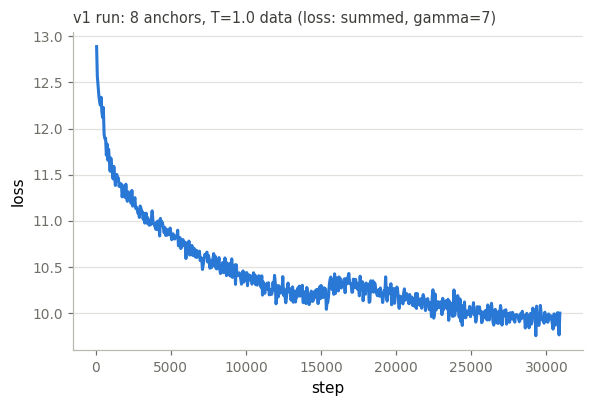

In [ ]:
import json
import matplotlib.pyplot as plt

INK, MUTE, GRID = '#3d3d3a', '#6f6e68', '#e3e2dc'
BLUE = '#2a78d6'

SRC = [
    ('v1 run: 8 anchors, T=1.0 data (loss: summed, gamma=7)',
     '/home/dev/KAP/data/pb_dspark/train_log.jsonl'),
    ('v2 Run A: 32 anchors, official recipe (loss: weighted mean, gamma=4)',
     '/home/dev/KAP/parameter/draft/dspark_pb_v2_a/loss_log.jsonl'),
    ('v2 Run B: 64 anchors, official recipe (loss: weighted mean, gamma=4)',
     '/home/dev/KAP/parameter/draft/dspark_pb_v2_b/loss_log.jsonl'),
]

have = []
for name, path in SRC:
    try:
        rows = [json.loads(l) for l in open(path)]
    except FileNotFoundError:
        continue
    tr = [r for r in rows if r.get('t') == 'train' or r.get('type') == 'train']
    if tr:
        have.append((name, tr))

if not have:
    print('目前没有 loss 记录：v2 的 A/B 启动时脚本尚未记录 loss（已修复，下次启动的训练自动写入 <out>/loss_log.jsonl）。')
else:
    fig, axes = plt.subplots(1, len(have), figsize=(5.5 * len(have), 3.8), dpi=110)
    axes = [axes] if len(have) == 1 else list(axes)
    for ax, (name, tr) in zip(axes, have):
        ax.plot([r['step'] for r in tr], [r['loss'] for r in tr], color=BLUE, lw=2)
        ax.set_xlabel('step'); ax.set_ylabel('loss')
        ax.set_title(name, fontsize=9.5, color=INK, loc='left')
        ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
        for s in ('left', 'bottom'): ax.spines[s].set_color('#b9b8b0')
        ax.tick_params(colors=MUTE, labelsize=9)
    fig.tight_layout()
    plt.show()

## 4. 评测一个 checkpoint（τ 复测）

加载 `best.pt`，在与训练完全相同的 200 条 val 上复算两个口径的 τ。**默认用 cuda:0**（运行 A 已结束、该卡空闲）；如果两张卡都在训练，等空闲再跑。需要约 4 GB 显存、约 1 分钟。

In [ ]:
import glob, math, sys
import torch
sys.path.insert(0, '/home/dev/KAP/src4dspark')
sys.path.insert(0, '/home/dev/KAP/train')
from transformers import AutoModelForImageTextToText, AutoTokenizer
from dspark_paper import DSparkDrafter, ND
from dspark_loss import make_blocks

P = '/home/dev/KAP/parameter/target/Qwen3.5-0.8B-Base-original'
W = '/home/dev/KAP/data/pb_dspark'
CKPT = '/home/dev/KAP/parameter/draft/dspark_pb_v2_a/best.pt'      # 想评别的权重就改这里，如 dspark_pb_v2_b/last.pt
DEV = 'cuda:0'

tok = AutoTokenizer.from_pretrained(P); EOS = tok.eos_token_id
items = {c['id']: c for c in torch.load(W + '/prompts.pt')}

def load_resp(d):
    r = {}
    for f in sorted(glob.glob(f'{W}/{d}/shard_r*_*.pt')):
        for x in torch.load(f):
            r[x['id']] = x['resp']
    return r

gen10, gen07 = load_resp('gen'), load_resp('gen07')
val10 = [{'id': i, 'prompt_ids': c['ids'], 'resp_ids': gen10[i]}
         for i, c in items.items() if c['split'] == 'val' and i in gen10 and len(gen10[i]) >= 16][:200]
val07 = [{'id': i, 'prompt_ids': c['ids'], 'resp_ids': gen07[i]}
         for i, c in items.items() if c['split'] == 'val' and i in gen07 and len(gen07[i]) >= 16][:200]

model = AutoModelForImageTextToText.from_pretrained(P, dtype=torch.bfloat16, device_map=DEV).eval()
for p in model.parameters():
    p.requires_grad_(False)
d = DSparkDrafter(model, n_draft=ND, layers=5, markov_rank=128, device=DEV, dtype=torch.float32)
ck = torch.load(CKPT, map_location=DEV, weights_only=False)
d.load_state_dict(ck['model']); d.eval()

@torch.inference_mode()
def tau(seqs, A=8, bs=16, seed=123):          # 与训练时 eval_tau 完全同协议
    g = torch.Generator().manual_seed(seed)
    al, n = None, 0
    for b0 in range(0, len(seqs), bs):
        feats, toks, o, p_t = make_blocks(model, EOS, seqs[b0:b0 + bs], A, g, 1.0, DEV)
        with torch.autocast('cuda', torch.bfloat16):
            z = d.backbone(d.encode_ctx(feats), d.embed(toks[..., 0]), o)
            lg = d.logits(z, toks[..., :ND]).float()
        q = torch.softmax(lg, -1)
        a = torch.minimum(p_t, q).sum(-1).mean((0, 1)).cpu()
        al = a if al is None else al + a
        n += 1
    al = (al / n).tolist()
    en = sum(math.prod(al[:k + 1]) for k in range(len(al)))
    return en + 1.0, al

for name, vs in (('τ_paper  (T=1.0 生成的 response)', val10), ('τ_indist (0.7/0.8/20 生成的 response)', val07)):
    t, al = tau(vs)
    a_str = ' '.join(f'{x:.2f}' for x in al)
    print(f'{name}: τ = {t:.3f}   α = {a_str}')
print(f"checkpoint: {CKPT}  step {ck.get('step')}  训练时记录 τ={ck.get('tau')}")

/home/dev/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Current Python version 3.10 is below the recommended 3.11 version. It is recommended to upgrade to Python 3.11 or higher for the best experience.
Loading weights: 100%|██████████| 473/473 [00:00<00:00, 1418.52it/s]


τ_paper  (T=1.0 生成的 response): τ = 2.133   α = 0.61 0.50 0.45 0.41 0.38 0.35 0.32
τ_indist (0.7/0.8/20 生成的 response): τ = 2.528   α = 0.71 0.60 0.52 0.47 0.43 0.40 0.38
checkpoint: /home/dev/KAP/parameter/draft/dspark_pb_v2_a/best.pt  step 30860  训练时记录 τ=2.1329917907714844


## 5. 常用操作备忘

```bash
# 断点续训（在原命令后加 --resume，其余不变）
... pb_train_v2.py --anchors 32 --seqs 16 --epochs 10 --out /home/dev/KAP/parameter/draft/dspark_pb_v2_a --resume

# 停掉训练（会丢未存盘的进度；每 1000 步存一次 last.pt，损失最多 1000 步）
pkill -f pb_train_v2.py

# 看实时日志
tail -f /home/dev/KAP/data/pb_dspark/train_v2_a.log

# 校验 gen07 数据是否齐全（每条 prompt 都有 response）
/home/dev/venv/bin/python -I /home/dev/KAP/train/pb_check_gen.py   # 旧数据；gen07 同理改目录
```

- **τ 怎么读**：τ_paper = 每轮平均接受 token 数（含 bonus），T=1.0 口径，与论文表 1 同定义；第一版 1.806 → v2 2.13+。τ_indist 是训练同分布（0.7 采样）上的值，只用于看拟合程度，不与论文直接比。
- 权重目录里 `best.pt` 按 τ_paper 最优保存，`last.pt` 是最近一次评测的完整恢复点（含优化器/调度状态，供 --resume）。
- 论文对齐情况与剩余差距（数据量、max_new、多轮）见 `doc/DSpark-训练文档.md` §12。

## 6. 域扩训练（dspark_domain）的曲线

混训（PB + countdown/ARC，从 v2-B 继续）的实时曲线：**左** = 每 50 步的训练 loss（`loss_log.jsonl`）；**右** = 每 1000 步的验证 τ（`train_log.jsonl`，τ_paper = PB 口径，τ_indist = 训练同分布口径）。训练结束后另有 countdown/ARC 域上的 τ_real 对比（`data/domain_exp/eval_before.json` / `eval_after.json`）。

In [ ]:
import json
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#2e8b57'
INK, MUTE, GRID = '#3d3d3a', '#6f6e68', '#e3e2dc'
DOM = '/home/dev/KAP/parameter/draft/dspark_domain'

def rows(path):
    try:
        return [json.loads(l) for l in open(path)]
    except FileNotFoundError:
        return []

loss = rows(DOM + '/loss_log.jsonl')
ev = rows(DOM + '/train_log.jsonl')
if not loss and not ev:
    print('dspark_domain 还没有产出记录（训练尚未开始或尚未到第一个记录点）。')
    print('进度看: tail -f /home/dev/KAP/data/domain_exp/train.log')
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=110)
    ax = axes[0]
    if loss:
        ax.plot([r['step'] for r in loss], [r['loss'] for r in loss], color=BLUE, lw=1.5, label='loss')
        ax.plot([r['step'] for r in loss], [r['ce'] for r in loss], color=ORANGE, lw=1.2, ls='--', label='ce')
        ax.legend(frameon=False, fontsize=9)
    ax.set_xlabel('step'); ax.set_ylabel('loss'); ax.set_title('train loss (every 50 steps)', fontsize=10, color=INK, loc='left')
    ax = axes[1]
    if ev:
        ax.plot([r['step'] for r in ev], [r['tau_paper'] for r in ev], color=BLUE, lw=2, label='tau_paper (PB)')
        ax.plot([r['step'] for r in ev], [r['tau_indist'] for r in ev], color=GREEN, lw=2, ls='--', label='tau_indist (0.7 data)')
        ax.legend(frameon=False, fontsize=9)
    ax.set_xlabel('step'); ax.set_ylabel('tau'); ax.set_title('val tau (every 1000 steps)', fontsize=10, color=INK, loc='left')
    for ax in axes:
        ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
        for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
        for s_ in ('left', 'bottom'): ax.spines[s_].set_color('#b9b8b0')
        ax.tick_params(colors=MUTE, labelsize=9)
    fig.suptitle('DSpark domain-expansion training (PB + countdown/ARC mix)', color=INK, fontsize=12, x=0.01, ha='left')
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

dspark_domain 还没有产出记录（训练尚未开始或尚未到第一个记录点）。
进度看: tail -f /home/dev/KAP/data/domain_exp/train.log


## 7. maze + sudoku 域扩训练曲线（dspark_maze_sudoku）

从 `dspark_domain/best.pt` 继续，混入 maze+sudoku 数据，2 epochs，lr=2e-4。
**左**：每 50 步训练 loss；**右**：每 1000 步验证 τ（τ_paper = PB val 口径，τ_indist = 同分布）。
训练完成后，`data/maze_sudoku/tau_before_after.json` 里有 maze/sudoku 域上的 before/after τ 对比。

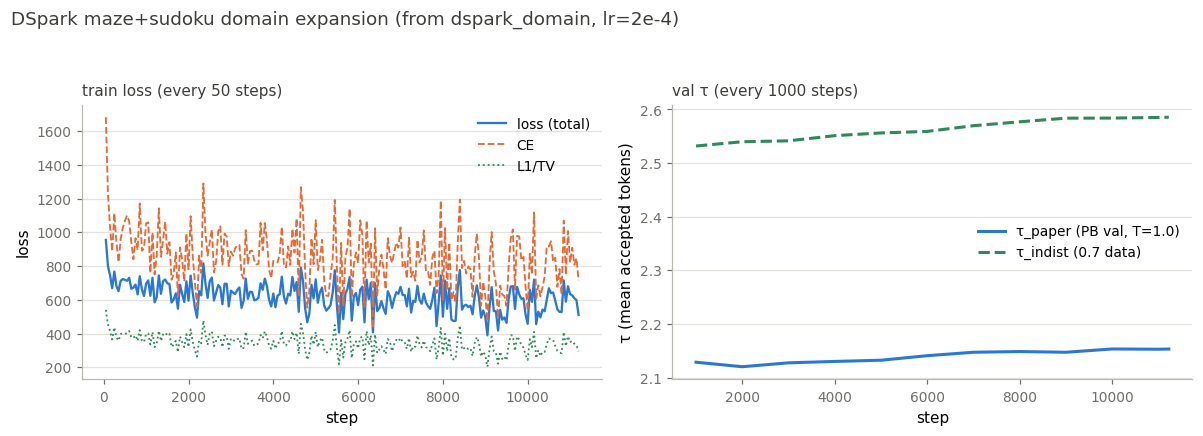


maze/sudoku domain τ (B=8 branches, 16 val prompts each):
                before     after     delta
maze             3.359     5.016    +1.658
sudoku           4.492     7.029    +2.537


In [1]:
import json
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#2e8b57'
INK, MUTE, GRID = '#3d3d3a', '#6f6e68', '#e3e2dc'
MS = '/home/dev/KAP/parameter/draft/dspark_maze_sudoku'

def rows(path):
    try:
        return [json.loads(l) for l in open(path)]
    except FileNotFoundError:
        return []

loss = rows(MS + '/loss_log.jsonl')
ev   = rows(MS + '/train_log.jsonl')

if not loss and not ev:
    print('dspark_maze_sudoku 还没有产出记录（训练尚未开始）。')
    print('进度看: tail -f /home/dev/KAP/data/maze_sudoku/train.log')
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=110)

    # --- left: loss ---
    ax = axes[0]
    if loss:
        ax.plot([r['step'] for r in loss], [r['loss'] for r in loss],
                color=BLUE, lw=1.5, label='loss (total)')
        ax.plot([r['step'] for r in loss], [r['ce']   for r in loss],
                color=ORANGE, lw=1.2, ls='--', label='CE')
        ax.plot([r['step'] for r in loss], [r['l1']   for r in loss],
                color=GREEN,  lw=1.2, ls=':',  label='L1/TV')
        ax.legend(frameon=False, fontsize=9)
    ax.set_xlabel('step'); ax.set_ylabel('loss')
    ax.set_title('train loss (every 50 steps)', fontsize=10, color=INK, loc='left')

    # --- right: tau ---
    ax = axes[1]
    if ev:
        ax.plot([r['step'] for r in ev], [r['tau_paper']  for r in ev],
                color=BLUE,  lw=2,   label='τ_paper (PB val, T=1.0)')
        ax.plot([r['step'] for r in ev], [r['tau_indist'] for r in ev],
                color=GREEN, lw=2, ls='--', label='τ_indist (0.7 data)')
        ax.legend(frameon=False, fontsize=9)
    ax.set_xlabel('step'); ax.set_ylabel('τ (mean accepted tokens)')
    ax.set_title('val τ (every 1000 steps)', fontsize=10, color=INK, loc='left')

    for ax in axes:
        ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
        for s in ('left', 'bottom'): ax.spines[s].set_color('#b9b8b0')
        ax.tick_params(colors=MUTE, labelsize=9)
    fig.suptitle('DSpark maze+sudoku domain expansion (from dspark_domain, lr=2e-4)',
                 color=INK, fontsize=12, x=0.01, ha='left')
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

# --- maze/sudoku before/after tau ---
try:
    ba = json.load(open('/home/dev/KAP/data/maze_sudoku/tau_before_after.json'))
    print('\nmaze/sudoku domain τ (B=8 branches, 16 val prompts each):')
    print(f"{'':12s}  {'before':>8s}  {'after':>8s}  {'delta':>8s}")
    for ds in ('maze', 'sudoku'):
        t0 = ba['before'][ds]['tau']
        t1 = ba['after'][ds]['tau']
        print(f"{ds:12s}  {t0:8.3f}  {t1:8.3f}  {t1-t0:+8.3f}")
except FileNotFoundError:
    print('\n(maze/sudoku before/after τ 对比：训练完成后自动写入 data/maze_sudoku/tau_before_after.json)')


## 8. n=4 对照实验曲线（dspark_n4 vs dspark_maze_sudoku）

同一个数据混合（PB + maze + sudoku），从 `dspark_maze_sudoku/best.pt` 切出 `mask_emb[:4]` 初始化，`--n-draft 4` 重训。
**上排**：训练 loss + 验证 τ 曲线（左 loss，右 τ）；n=4 与 n=7 画在同一图里直接对比。
**下排**：推理时 n=4 模型（infer n=4）vs n=7 模型（infer n=6，之前 sweep 的峰值点）在 PB/maze/sudoku/countdown 四个域上的 τ 与 tok/s。数据来自 `test_n4_vs_n7.py` 写入的 `dspark_n4/compare_results.json`。

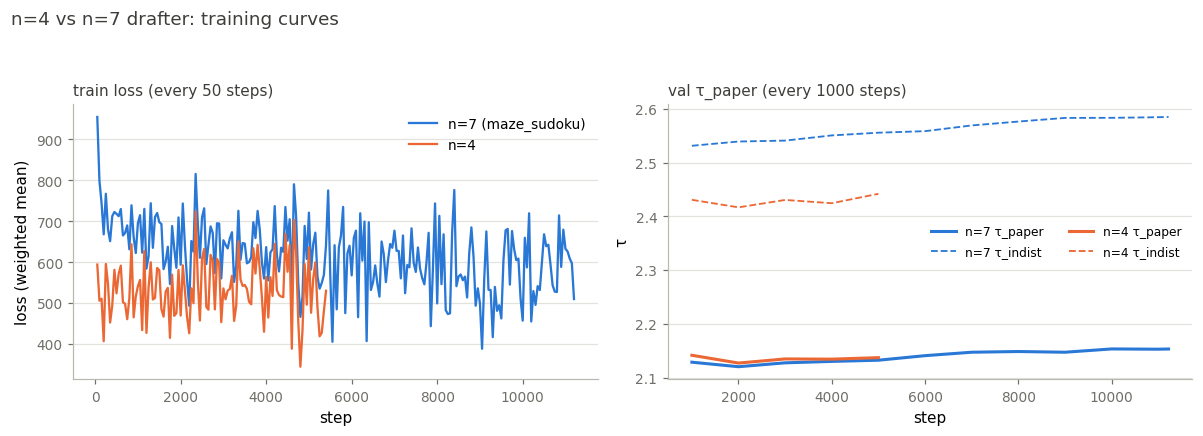


(n=4 推理对比：n=4 训练完成后自动写入 dspark_n4/compare_results.json)


In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np

BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#2e8b57'
INK, MUTE, GRID = '#3d3d3a', '#6f6e68', '#e3e2dc'
N4  = '/home/dev/KAP/parameter/draft/dspark_n4'
MS  = '/home/dev/KAP/parameter/draft/dspark_maze_sudoku'

def rows(path):
    try:
        return [json.loads(l) for l in open(path)]
    except FileNotFoundError:
        return []

n4_loss = rows(N4 + '/loss_log.jsonl')
n4_ev   = rows(N4 + '/train_log.jsonl')
ms_loss = rows(MS + '/loss_log.jsonl')
ms_ev   = rows(MS + '/train_log.jsonl')

have_curves = n4_loss or n4_ev or ms_loss or ms_ev
if not have_curves:
    print('n=4 训练尚未开始（maze_sudoku 训练完成后自动启动）。')
    print('watcher 进度: tail -f /home/dev/KAP/data/maze_sudoku/n4_run.log')
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=110)

    # left: loss
    ax = axes[0]
    if ms_loss:
        ax.plot([r['step'] for r in ms_loss], [r['loss'] for r in ms_loss],
                color=BLUE, lw=1.5, label='n=7 (maze_sudoku)')
    if n4_loss:
        ax.plot([r['step'] for r in n4_loss], [r['loss'] for r in n4_loss],
                color=ORANGE, lw=1.5, label='n=4')
    ax.set_xlabel('step'); ax.set_ylabel('loss (weighted mean)')
    ax.set_title('train loss (every 50 steps)', fontsize=10, color=INK, loc='left')
    ax.legend(frameon=False, fontsize=9)

    # right: tau_paper
    ax = axes[1]
    if ms_ev:
        ax.plot([r['step'] for r in ms_ev], [r['tau_paper'] for r in ms_ev],
                color=BLUE, lw=2, label='n=7 τ_paper')
        ax.plot([r['step'] for r in ms_ev], [r['tau_indist'] for r in ms_ev],
                color=BLUE, lw=1.2, ls='--', label='n=7 τ_indist')
    if n4_ev:
        ax.plot([r['step'] for r in n4_ev], [r['tau_paper'] for r in n4_ev],
                color=ORANGE, lw=2, label='n=4 τ_paper')
        ax.plot([r['step'] for r in n4_ev], [r['tau_indist'] for r in n4_ev],
                color=ORANGE, lw=1.2, ls='--', label='n=4 τ_indist')
    ax.set_xlabel('step'); ax.set_ylabel('τ')
    ax.set_title('val τ_paper (every 1000 steps)', fontsize=10, color=INK, loc='left')
    ax.legend(frameon=False, fontsize=8, ncol=2)

    for ax in axes:
        ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
        for s in ('left', 'bottom'): ax.spines[s].set_color('#b9b8b0')
        ax.tick_params(colors=MUTE, labelsize=9)
    fig.suptitle('n=4 vs n=7 drafter: training curves', color=INK, fontsize=12, x=0.01, ha='left')
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

# --- inference comparison bar chart ---
try:
    cmp = json.load(open(N4 + '/compare_results.json'))
    r4, r7 = cmp['n4'], cmp['n7_at_6']
    domains = [d for d in r4 if d in r7]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=110)
    x = np.arange(len(domains)); w = 0.35

    ax = axes[0]
    ax.bar(x - w/2, [r4[d]['tau'] for d in domains], w, color=ORANGE, label='n=4 (infer n=4)')
    ax.bar(x + w/2, [r7[d]['tau'] for d in domains], w, color=BLUE,   label='n=7 (infer n=6)')
    ax.set_xticks(x); ax.set_xticklabels(domains)
    ax.set_ylabel('τ (mean accepted tokens)'); ax.set_title('τ by domain', fontsize=10, color=INK, loc='left')
    ax.legend(frameon=False, fontsize=9)

    ax = axes[1]
    ax.bar(x - w/2, [r4[d]['tok_s'] for d in domains], w, color=ORANGE, label='n=4 (infer n=4)')
    ax.bar(x + w/2, [r7[d]['tok_s'] for d in domains], w, color=BLUE,   label='n=7 (infer n=6)')
    ax.set_xticks(x); ax.set_xticklabels(domains)
    ax.set_ylabel('tok/s'); ax.set_title('throughput by domain', fontsize=10, color=INK, loc='left')
    ax.legend(frameon=False, fontsize=9)

    for ax in axes:
        ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
        for s in ('left', 'bottom'): ax.spines[s].set_color('#b9b8b0')
        ax.tick_params(colors=MUTE, labelsize=9)
    fig.suptitle('n=4 vs n=7 drafter: inference comparison (B=4 branches)', color=INK, fontsize=12, x=0.01, ha='left')
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

    print('\n推理结果汇总:')
    print(f"{'domain':12s}  {'n4 τ':>7s}  {'n7@6 τ':>7s}  {'Δτ':>7s}  {'n4 tok/s':>10s}  {'n7@6 tok/s':>10s}")
    for d in domains:
        t4, t7 = r4[d]['tau'], r7[d]['tau']
        s4, s7 = r4[d]['tok_s'], r7[d]['tok_s']
        print(f"{d:12s}  {t4:7.3f}  {t7:7.3f}  {t4-t7:+7.3f}  {s4:10.1f}  {s7:10.1f}")
except FileNotFoundError:
    print('\n(n=4 推理对比：n=4 训练完成后自动写入 dspark_n4/compare_results.json)')
